# A/B-тест email-рассылки (Hillstrom): анализ и uplift-модель

**Часть 1: данные, дизайн теста, A/B-анализ.**

Контекст: интернет-магазин разослал клиентам письма двух видов (мужская и женская подборка) и оставил контрольную группу без письма.
Нужно ответить на вопрос бизнеса: **стоит ли отправлять письма и какое именно?**

План ноутбука:
1. Знакомство с данными и проверка качества
2. Дизайн теста: гипотезы, метрики, SRM, баланс групп, мощность
3. A/B-анализ: конверсия, визиты, траты, выводы

In [1]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint, proportion_effectsize
from statsmodels.stats.power import NormalIndPower

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# Путь находит файл и на Kaggle, и локально
paths = glob.glob("/kaggle/input/**/*Hillstrom*.csv", recursive=True) \
     or glob.glob("/kaggle/input/**/*.csv", recursive=True) \
     or glob.glob("../archive/*.csv")
df = pd.read_csv(paths[0])
print("Файл:", paths[0])
df.shape

Файл: /kaggle/input/datasets/sumittarya/hillstrom-email-marketing/Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv


(64000, 12)

## 1. Знакомство с данными

Колонки:
- `recency` – месяцев с последней покупки; `history`, `history_segment` – сумма покупок за прошлый год
- `mens`, `womens` – покупал ли мужские или женские товары
- `zip_code` – тип района; `newbie` – новый клиент (1) или нет (0); `channel` – канал покупок
- `segment` – **группа теста**: `Mens E-Mail`, `Womens E-Mail`, `No E-Mail` (контроль)
- `visit`, `conversion`, `spend` – результаты за две недели после рассылки

In [2]:
display(df.head())
display(df.dtypes.to_frame("dtype").T)
print("Пропуски:", int(df.isna().sum().sum()))
print("Полных дублей строк:", int(df.duplicated().sum()))

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.4400,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0000
1,6,3) $200 - $350,329.0800,1,1,Rural,1,Web,No E-Mail,0,0,0.0000
2,7,2) $100 - $200,180.6500,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0000
3,9,5) $500 - $750,675.8300,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0000
4,2,1) $0 - $100,45.3400,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0000


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
dtype,int64,object,float64,int64,int64,object,int64,object,object,int64,int64,float64


Пропуски: 0
Полных дублей строк: 6562


Полные дубли строк здесь ничего не значат: в данных нет id клиента, поэтому два разных клиента могут иметь одинаковые значения признаков.
Поэтому дубли не удаляем.

In [3]:
display(df.describe().T)

# Целевые метрики: проверяем, что значения корректны
assert df["visit"].isin([0, 1]).all() and df["conversion"].isin([0, 1]).all()
assert (df["spend"] >= 0).all()
# Покупка без визита была бы нелогична
print("Конверсий без визита:", int(((df.conversion == 1) & (df.visit == 0)).sum()))
print("Трата > 0 без конверсии:", int(((df.spend > 0) & (df.conversion == 0)).sum()))

,count,mean,std,min,25%,50%,75%,max
recency,"64,000.0000",5.7637,3.5076,1.0000,2.0000,6.0000,9.0000,12.0000
history,"64,000.0000",242.0857,256.1586,29.9900,64.6600,158.1100,325.6575,"3,345.9300"
mens,"64,000.0000",0.5510,0.4974,0.0000,0.0000,1.0000,1.0000,1.0000
womens,"64,000.0000",0.5497,0.4975,0.0000,0.0000,1.0000,1.0000,1.0000
newbie,"64,000.0000",0.5022,0.5000,0.0000,0.0000,1.0000,1.0000,1.0000
visit,"64,000.0000",0.1468,0.3539,0.0000,0.0000,0.0000,0.0000,1.0000
conversion,"64,000.0000",0.0090,0.0946,0.0000,0.0000,0.0000,0.0000,1.0000
spend,"64,000.0000",1.0509,15.0364,0.0000,0.0000,0.0000,0.0000,499.0000


Конверсий без визита: 0
Трата > 0 без конверсии: 0


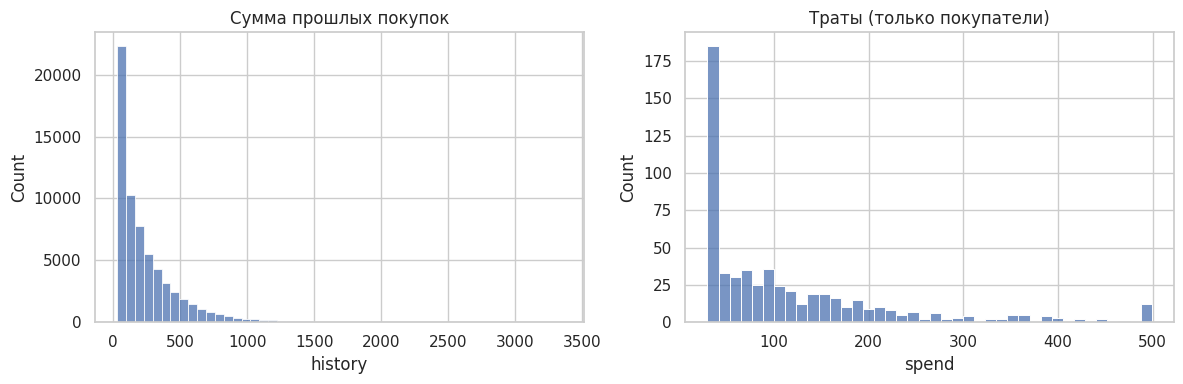

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["history"], bins=50, ax=axes[0]).set(title="Сумма прошлых покупок")
sns.histplot(df.loc[df.spend > 0, "spend"], bins=40, ax=axes[1]).set(title="Траты (только покупатели)")
plt.tight_layout(); plt.show()

Траты сильно скошены вправо (много маленьких покупок, мало больших), а покупателей мало. Это важно для выбора метода: для трат кроме t-теста возьмём ещё бутстрап.

## 2. Дизайн теста

### Гипотезы
Сравниваем каждое письмо с контролем (`No E-Mail`).

- **H0:** письмо не влияет на конверсию в покупку.
- **H1:** письмо меняет конверсию (двусторонняя проверка).

### Метрики
| Тип | Метрика | Почему |
|---|---|---|
| Основная | `conversion` (доля купивших) | Прямая бизнес-цель рассылки |
| Вторичные | `visit` (доля зашедших), `spend` (средняя сумма на клиента) | Показывают механизм эффекта и деньги |

### Уровень значимости
Сравнений с контролем два, поэтому применяем **поправку Бонферрони**: α = 0,05 / 2 = 0,025.

In [5]:
ALPHA = 0.05
N_COMPARISONS = 2
ALPHA_ADJ = ALPHA / N_COMPARISONS

groups = ["No E-Mail", "Mens E-Mail", "Womens E-Mail"]
sizes = df["segment"].value_counts().reindex(groups)
display(sizes.to_frame("n"))

,n
segment,
No E-Mail,21306
Mens E-Mail,21307
Womens E-Mail,21387


### Проверка SRM (Sample Ratio Mismatch)
Если рассылка делилась случайно на три равные части, в каждой группе должно быть примерно по 1/3 клиентов. Проверяем хи-квадратом.
Маленький p-value значил бы, что распределение нарушено и результатам теста доверять нельзя.

In [6]:
expected = np.repeat(len(df) / 3, 3)
chi2, p_srm = stats.chisquare(sizes.values, expected)
print(f"SRM: chi2 = {chi2:.3f}, p-value = {p_srm:.4f}")
print("Вывод:", "нарушение деления групп" if p_srm < 0.001 else "деление групп в порядке")

SRM: chi2 = 0.203, p-value = 0.9037
Вывод: деление групп в порядке


### Баланс групп по признакам
При случайном делении признаки клиентов должны быть распределены одинаково во всех группах. Проверяем это.

In [7]:
cat_cols = ["newbie", "mens", "womens", "zip_code", "channel", "history_segment"]
rows = []
for c in cat_cols:
    chi2_c, p_c, _, _ = stats.chi2_contingency(pd.crosstab(df["segment"], df[c]))
    rows.append((c, p_c))
for c in ["recency", "history"]:
    f, p_c = stats.f_oneway(*[df.loc[df.segment == g, c] for g in groups])
    rows.append((c, p_c))
balance = pd.DataFrame(rows, columns=["признак", "p-value"])
balance["баланс"] = np.where(balance["p-value"] > 0.05, "ок", "проверить")
display(balance)

,признак,p-value,баланс
0,newbie,0.9339,ок
1,mens,0.6717,ок
2,womens,0.7289,ок
3,zip_code,0.5795,ок
4,channel,0.4580,ок
5,history_segment,0.3580,ок
6,recency,0.7631,ок
7,history,0.6980,ок


Если p-value больше 0,05 для всех признаков, группы сопоставимы и различия в результатах можно приписать письму, а не составу групп.
Один-два «проверить» при 8 признаках могут появиться случайно: при α = 0,05 в среднем 1 из 20 проверок срабатывает впустую.

### Мощность и минимальный обнаруживаемый эффект (MDE)
Какой минимальный рост конверсии тест мог надёжно заметить при таких размерах групп?

Базовая конверсия контроля: 0.5726%, n на группу ≈ 21306
MDE при мощности 80% и α = 0.025: рост конверсии на 44% относительно базы (0.573% → 0.825%)


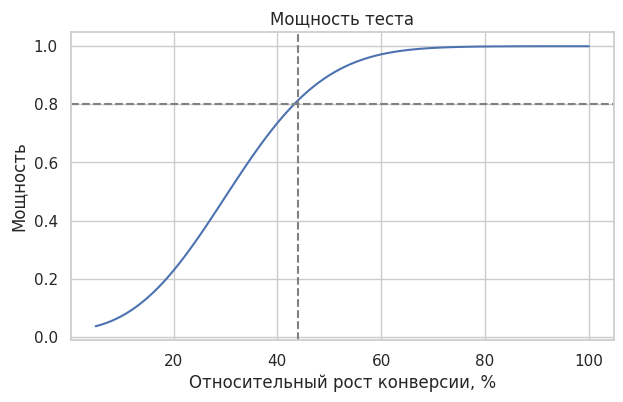

In [8]:
ctrl = df[df.segment == "No E-Mail"]
n_ctrl = len(ctrl)
p0 = ctrl["conversion"].mean()
print(f"Базовая конверсия контроля: {p0:.4%}, n на группу ≈ {n_ctrl}")

analysis = NormalIndPower()
lifts = np.linspace(0.05, 1.0, 96)  # относительный рост конверсии
power = [analysis.power(proportion_effectsize(p0 * (1 + l), p0), nobs1=n_ctrl, alpha=ALPHA_ADJ, ratio=1) for l in lifts]

mde_rel = next(l for l, pw in zip(lifts, power) if pw >= 0.8)
print(f"MDE при мощности 80% и α = {ALPHA_ADJ}: рост конверсии на {mde_rel:.0%} относительно базы "
      f"({p0:.3%} → {p0 * (1 + mde_rel):.3%})")

plt.figure(figsize=(7, 4))
plt.plot(lifts * 100, power)
plt.axhline(0.8, ls="--", c="gray")
plt.axvline(mde_rel * 100, ls="--", c="gray")
plt.xlabel("Относительный рост конверсии, %"); plt.ylabel("Мощность"); plt.title("Мощность теста")
plt.show()

Конверсия в данных низкая (меньше 1%), поэтому для надёжного обнаружения нужен заметный относительный рост. Это ограничение стоит помнить, когда будем читать результат: «нет значимого эффекта» тут не значит «эффекта нет».

## 3. A/B-анализ

In [9]:
def summarize(group):
    d = df[df.segment == group]
    n = len(d)
    return pd.Series({
        "n": n,
        "visit_rate": d["visit"].mean(),
        "conversion_rate": d["conversion"].mean(),
        "spend_per_user": d["spend"].mean(),
    })

summary = pd.DataFrame({g: summarize(g) for g in groups}).T
display(summary)

,n,visit_rate,conversion_rate,spend_per_user
No E-Mail,"21,306.0000",0.1062,0.0057,0.6528
Mens E-Mail,"21,307.0000",0.1828,0.0125,1.4226
Womens E-Mail,"21,387.0000",0.1514,0.0088,1.0772


### Конверсия и визиты: z-тест для долей
Для каждого письма считаем разницу с контролем, 95%-й доверительный интервал разницы и p-value. Решение принимаем по скорректированному α.

In [10]:
def prop_test(metric, treat, control="No E-Mail"):
    t = df[df.segment == treat][metric]
    c = df[df.segment == control][metric]
    count = np.array([t.sum(), c.sum()])
    nobs = np.array([len(t), len(c)])
    _, p = proportions_ztest(count, nobs)
    pt, pc = t.mean(), c.mean()
    diff = pt - pc
    se = np.sqrt(pt * (1 - pt) / len(t) + pc * (1 - pc) / len(c))
    ci_low, ci_high = diff - 1.96 * se, diff + 1.96 * se
    return {
        "метрика": metric, "группа": treat,
        "контроль": pc, "тест": pt,
        "разница (п.п.)": diff * 100, "CI95 низ (п.п.)": ci_low * 100, "CI95 верх (п.п.)": ci_high * 100,
        "относит. рост": diff / pc, "p-value": p,
        "значимо (Бонферрони)": p < ALPHA_ADJ,
    }

res_prop = pd.DataFrame([prop_test(m, g) for m in ["conversion", "visit"] for g in ["Mens E-Mail", "Womens E-Mail"]])
display(res_prop)

,метрика,группа,контроль,тест,разница (п.п.),CI95 низ (п.п.),CI95 верх (п.п.),относит. рост,p-value,значимо (Бонферрони)
0,conversion,Mens E-Mail,0.0057,0.0125,0.6805,0.5000,0.8610,1.1884,0.0000,True
1,conversion,Womens E-Mail,0.0057,0.0088,0.3111,0.1499,0.4723,0.5433,0.0002,True
2,visit,Mens E-Mail,0.1062,0.1828,7.6590,6.9953,8.3226,0.7214,0.0000,True
3,visit,Womens E-Mail,0.1062,0.1514,4.5233,3.8894,5.1573,0.4261,0.0000,True


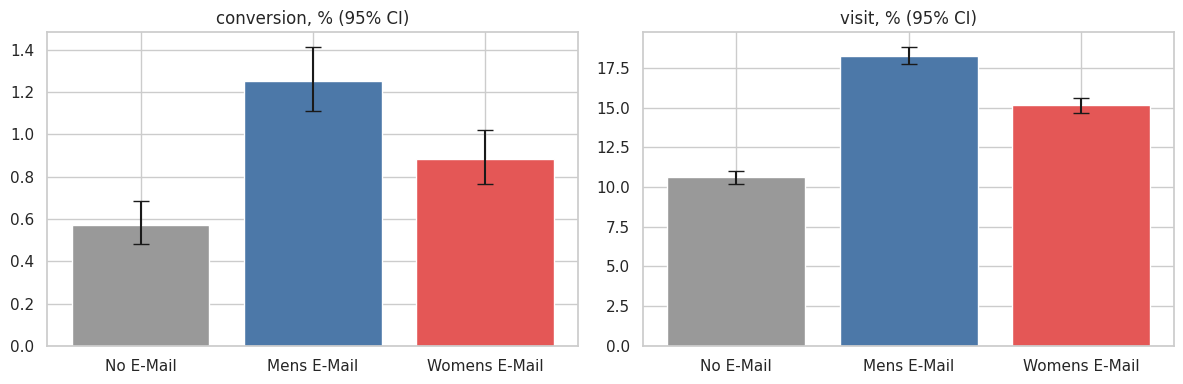

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["conversion", "visit"]):
    rates, errs = [], []
    for g in groups:
        d = df[df.segment == g][metric]
        lo, hi = proportion_confint(d.sum(), len(d), method="wilson")
        rates.append(d.mean() * 100)
        errs.append([d.mean() * 100 - lo * 100, hi * 100 - d.mean() * 100])
    ax.bar(groups, rates, yerr=np.array(errs).T, capsize=6, color=["#999", "#4c78a8", "#e45756"])
    ax.set_title(f"{metric}, % (95% CI)")
plt.tight_layout(); plt.show()

### Траты: t-тест Уэлча и бутстрап
Траты скошены и в основном состоят из нулей, поэтому проверяем двумя способами: классическим t-тестом и бутстрапом разницы средних (он не требует нормальности).

In [12]:
rng = np.random.default_rng(42)

def spend_test(treat, control="No E-Mail", n_boot=5000):
    t = df[df.segment == treat]["spend"].to_numpy()
    c = df[df.segment == control]["spend"].to_numpy()
    _, p = stats.ttest_ind(t, c, equal_var=False)
    boots = np.empty(n_boot)
    for i in range(n_boot):
        boots[i] = rng.choice(t, len(t)).mean() - rng.choice(c, len(c)).mean()
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return {
        "группа": treat, "контроль $": c.mean(), "тест $": t.mean(),
        "разница $": t.mean() - c.mean(), "бутстрап CI95 низ": lo, "бутстрап CI95 верх": hi,
        "p-value (Уэлч)": p, "значимо (Бонферрони)": p < ALPHA_ADJ,
    }

res_spend = pd.DataFrame([spend_test(g) for g in ["Mens E-Mail", "Womens E-Mail"]])
display(res_spend)

,группа,контроль $,тест $,разница $,бутстрап CI95 низ,бутстрап CI95 верх,p-value (Уэлч),значимо (Бонферрони)
0,Mens E-Mail,0.6528,1.4226,0.7698,0.4791,1.0492,0.0000,True
1,Womens E-Mail,0.6528,1.0772,0.4244,0.1657,0.6942,0.0011,True


### Mens против Womens
Какое письмо лучше? Прямое сравнение между двумя письмами. Это третье сравнение, поэтому не забываем про множественность.

In [13]:
res_mw = pd.DataFrame([prop_test(m, "Mens E-Mail", control="Womens E-Mail") for m in ["conversion", "visit"]])
display(res_mw)

,метрика,группа,контроль,тест,разница (п.п.),CI95 низ (п.п.),CI95 верх (п.п.),относит. рост,p-value,значимо (Бонферрони)
0,conversion,Mens E-Mail,0.0088,0.0125,0.3694,0.1743,0.5644,0.4180,0.0002,True
1,visit,Mens E-Mail,0.1514,0.1828,3.1356,2.4285,3.8428,0.2071,0.0000,True


## Выводы по A/B-анализу

**Качество теста.** Деление на группы честное: SRM не обнаружен (p = 0,90), все 8 признаков сбалансированы между группами (p от 0,36 до 0,93). Различия в результатах можно приписать письму, а не составу групп.

**Эффект рассылки.** Оба письма значимо улучшают все метрики относительно контроля (порог с поправкой Бонферрони: α = 0,025):

| Метрика | Контроль | Mens E-Mail | Womens E-Mail |
|---|---|---|---|
| Визиты | 10,6% | 18,3% (+7,7 п.п.) | 15,1% (+4,5 п.п.) |
| Конверсия | 0,57% | 1,25% (+0,68 п.п., ×2,2) | 0,88% (+0,31 п.п., +54%) |
| Трата на клиента | $0,65 | $1,42 (+$0,77) | $1,08 (+$0,42) |

95%-е доверительные интервалы разницы нигде не включают ноль: для конверсии Mens это [0,50; 0,86] п.п., для Womens [0,15; 0,47] п.п. Бутстрап по тратам подтверждает t-тест: Mens [+$0,48; +$1,05], Womens [+$0,17; +$0,69] на клиента.

**Какое письмо лучше.** Mens-письмо превосходит Womens по конверсии (+0,37 п.п., p = 0,0002) и по визитам (+3,1 п.п., p < 0,0001). Результат устойчив и к дополнительной поправке на третье сравнение.

**Окупаемость.** Каждое отправленное письмо приносит в среднем дополнительные $0,77 (Mens) или $0,42 (Womens) выручки. Рассылка выгодна, если стоимость отправки одного письма ниже этих сумм.

**Мощность.** При 21 тыс. клиентов в группе и базовой конверсии 0,57% тест надёжно обнаруживает эффект от +44% относительно базы. Наблюдаемые эффекты (+119% и +54%) выше этого порога, поэтому вывод надёжен. Более мелкие различия, например между двумя письмами по тратам, на таком объёме обнаружить трудно.

**Ограничения.**
- Покупок мало (меньше 1% клиентов), поэтому оценка трат шумная, интервалы широкие.
- Данные охватывают две недели после рассылки: долгосрочный эффект и возможная усталость от писем не видны.
- Результат средний по всем клиентам. Для части клиентов письмо может быть бесполезным или вредным.

**Рекомендация.** Отправлять письма, начиная с Mens-варианта. Следующий шаг: найти сегменты клиентов, где эффект сильнее или отрицательный, и построить uplift-модель для таргетинга.